<a href="https://colab.research.google.com/github/raco-dot/Actividad5-Banca-MLflow/blob/main/entrena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 5 — Bank Marketing (UCI)
Comparación reproducible de regresión logística y Random Forest con MLflow.

Continuaremos con la idea de manejar operaciones y conceptos bancarios

Primero instalaremos el ambiente y el MLflow

In [5]:
%pip install -q "mlflow>=3,<4" "scikit-learn>=1.3,<2"


In [6]:
import os, mlflow
os.environ["MLFLOW_TRACKING_URI"] = "sqlite:////content/mlflow.db"
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
mlflow.set_experiment("Actividad5_Banca")
print("MLflow listo:", mlflow.get_tracking_uri())


MLflow listo: sqlite:////content/mlflow.db


## Cargar ZIP del proyecto
Sube el ZIP recibido mediante el selector.

El archivo corresponde al paquete de código y recursos del proyecto, lo preparé previamente para facilitar la reproducción en Colab.

In [7]:
from google.colab import files
subidos=files.upload()
archivo=next((k for k in subidos if k.endswith(".zip")),None)
assert archivo, "Sube el ZIP del proyecto"
import zipfile,os
with zipfile.ZipFile(archivo) as z: z.extractall("/content/proyecto")
ROOT="/content/proyecto/Actividad5"
assert os.path.exists(ROOT+"/fuentes/train.py")
print("Proyecto listo:",ROOT)

Saving Actividad5_Banca_corregida.zip to Actividad5_Banca_corregida (1).zip
Proyecto listo: /content/proyecto/Actividad5


In [10]:
from pathlib import Path

archivo = Path(ROOT) / "fuentes" / "train.py"

codigo = archivo.read_text(encoding="utf-8")

original = "mlflow.sklearn.log_model(fitted,name='modelo')"

corregido = (
    "mlflow.sklearn.log_model("
    "fitted, name='modelo', "
    "serialization_format='cloudpickle')"
)

assert original in codigo, (
    "No se encontró la instrucción original. "
    "No se ha modificado el archivo."
)

codigo = codigo.replace(original, corregido)

archivo.write_text(codigo, encoding="utf-8")

print("train.py corregido correctamente")

train.py corregido correctamente


## Entrenamiento y MLflow
Descarga UCI, prepara datos, entrena y registra modelos. Puede tardar varios minutos.

Esta sección ejecuta train.py para:
  - preparar los datos bancarios
  - entrenar regresión logística y Random Forest
  - optimizar hiperparámetros
  - y registrar los resultados en MLflow.
Finalmente, muestra la salida del programa y posibles errores, facilitando la trazabilidad y reproducibilidad del experimento.

In [11]:
import subprocess
import sys
import os

env = os.environ.copy()
env["MLFLOW_TRACKING_URI"] = "sqlite:////content/mlflow.db"

resultado = subprocess.run(
    [sys.executable, ROOT + "/fuentes/train.py"],
    env=env,
    cwd=ROOT,
    capture_output=True,
    text=True
)

print("=== SALIDA DEL PROGRAMA ===")
print(resultado.stdout)

print("=== DETALLE DEL ERROR ===")
print(resultado.stderr)

print("Código de salida:", resultado.returncode)

=== SALIDA DEL PROGRAMA ===
Regresion_logistica {'accuracy': 0.7578271932735922, 'precision': 0.2707742197000405, 'recall': 0.6313799621928167, 'f1': 0.3790070921985816, 'roc_auc': np.float64(0.7735002246592747)} {'model__C': 10.0, 'model__class_weight': 'balanced'}
Random_forest {'accuracy': 0.8939041929416971, 'precision': 0.6523076923076923, 'recall': 0.2003780718336484, 'f1': 0.3065798987707881, 'roc_auc': np.float64(0.8033047059545247)} {'model__max_depth': 16, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Resultados guardados en /content/proyecto/Actividad5/resultados
Tracking MLflow: sqlite:////content/mlflow.db

=== DETALLE DEL ERROR ===
2026/11/11 04:28:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more inform

## Ver resultados

,modelo,accuracy,precision,recall,f1,roc_auc,cv_f1_mean,cv_f1_std,best_params
0,Regresion_logistica,0.757827,0.270774,0.631380,0.379007,0.773500,0.371326,0.008498,"{""model__C"": 10.0, ""model__class_weight"": ""bal..."
1,Random_forest,0.893904,0.652308,0.200378,0.306580,0.803305,0.314719,0.019949,"{""model__max_depth"": 16, ""model__min_samples_l..."


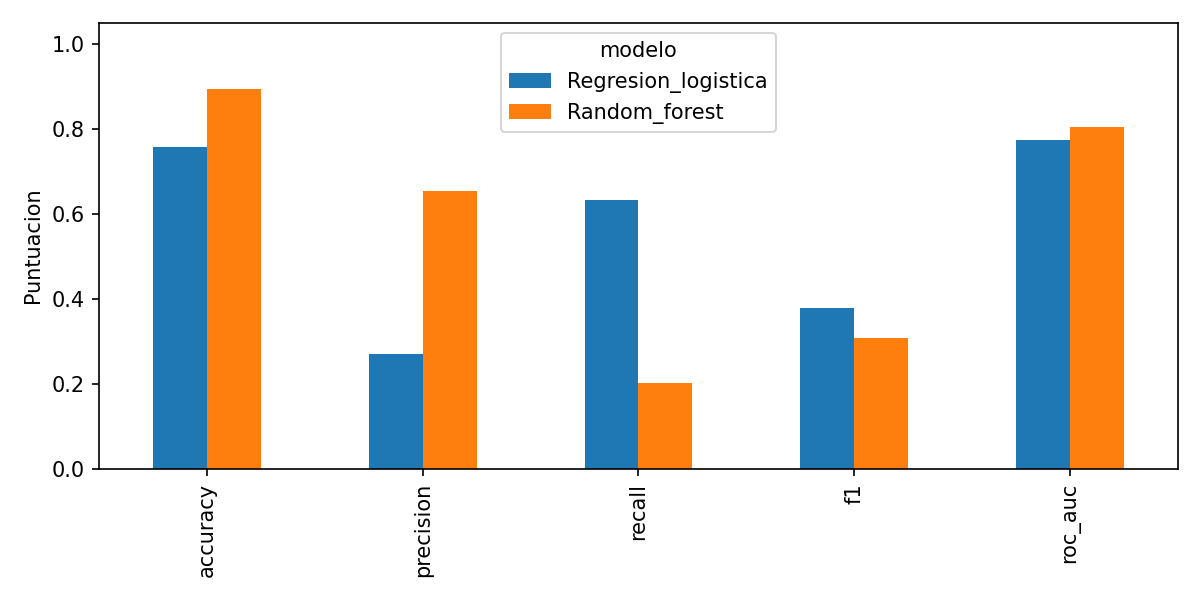

In [12]:
import pandas as pd
display(pd.read_csv(ROOT+"/resultados/comparacion_modelos.csv"))
from IPython.display import display,Image
display(Image(filename=ROOT+"/graficas/comparacion_metricas.png"))

## Evidencia MLflow

Esta celda comprueba si el servidor MLflow está activo y, en caso contrario, lo inicia utilizando la base de datos SQLite del proyecto. Posteriormente, intenta mostrar su interfaz en Google Colab para consultar las ejecuciones, comparar parámetros y métricas, y obtener evidencias visuales de los experimentos realizados.

In [13]:
import requests, subprocess, time
from google.colab import output
try:
    r = requests.get("http://127.0.0.1:5000/", timeout=3)
    print("Servidor ya activo:", r.status_code)
except requests.RequestException:
    server = subprocess.Popen(["mlflow", "server", "--backend-store-uri", "sqlite:////content/mlflow.db", "--host", "127.0.0.1", "--port", "5000"], stdout=open("/content/mlflow_server.log", "w"), stderr=subprocess.STDOUT)
    time.sleep(5)
output.serve_kernel_port_as_iframe(5000)


<IPython.core.display.Javascript object>

## Exportar entrega actualizada
El ZIP incluye los resultados reales, los gráficos y el directorio MLflow. Agrega después las capturas al PDF/ZIP para la entrega final.

In [14]:
import shutil, os
from google.colab import files
os.makedirs(ROOT + "/evidencias", exist_ok=True)
shutil.copy2("/content/mlflow.db", ROOT + "/evidencias/mlflow.db")
if os.path.isdir("/content/mlruns"):
    shutil.copytree("/content/mlruns", ROOT + "/evidencias/mlruns", dirs_exist_ok=True)
salida=shutil.make_archive("/content/Actividad5_Banca_resultados", "zip", "/content/proyecto")
files.download(salida)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>